In [1]:
%pip install geopandas pyogrio folium mapclassify matplotlib

   ---------------------------------------- 0.0/23.8 MB ? eta -:--:--
   ----- ---------------------------------- 3.1/23.8 MB 15.5 MB/s eta 0:00:02
   -------------- ------------------------- 8.4/23.8 MB 20.8 MB/s eta 0:00:01
   ------------------------------ --------- 18.4/23.8 MB 30.6 MB/s eta 0:00:01
   ---------------------------------------- 23.8/23.8 MB 33.2 MB/s  0:00:00
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ------------------------------- -------- 7.6/9.5 MB 54.6 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 34.0 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 65.9 MB/s  0:00:00
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 2.1/2.1 MB 64.8 MB/s  0:00:00
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   ----------------------------------------

In [2]:
import geopandas as gpd
import pyogrio
from pathlib import Path

data = Path("data")
files = sorted(data.glob("*.gpkg"))

for f in files:
    print("\n==", f.name)
    for layer in pyogrio.list_layers(f):
        print("   layer:", layer[0])


== G04A_VIC_GDA2020.gpkg
   layer: G04A_GCCSA_2021_VIC
   layer: G04A_UCL_2021_VIC
   layer: G04A_SUA_2021_VIC
   layer: G04A_SOSR_2021_VIC
   layer: G04A_SOS_2021_VIC
   layer: G04A_CED_2021_VIC
   layer: G04A_LGA_2021_VIC
   layer: G04A_POA_2021_VIC
   layer: G04A_SA1_2021_VIC
   layer: G04A_SA2_2021_VIC
   layer: G04A_SA3_2021_VIC
   layer: G04A_SA4_2021_VIC
   layer: G04A_SAL_2021_VIC
   layer: G04A_SED_2021_VIC
   layer: G04A_STE_2021_VIC
   layer: G04A_RA_2021_VIC

== G04B_VIC_GDA2020.gpkg
   layer: G04B_GCCSA_2021_VIC
   layer: G04B_UCL_2021_VIC
   layer: G04B_SUA_2021_VIC
   layer: G04B_SOSR_2021_VIC
   layer: G04B_SOS_2021_VIC
   layer: G04B_CED_2021_VIC
   layer: G04B_LGA_2021_VIC
   layer: G04B_POA_2021_VIC
   layer: G04B_SA1_2021_VIC
   layer: G04B_SA2_2021_VIC
   layer: G04B_SA3_2021_VIC
   layer: G04B_SA4_2021_VIC
   layer: G04B_SAL_2021_VIC
   layer: G04B_SED_2021_VIC
   layer: G04B_STE_2021_VIC
   layer: G04B_RA_2021_VIC

== G34_VIC_GDA2020.gpkg
   layer: G34_GCCSA_202

In [3]:
for f in files:
    layers = pyogrio.list_layers(f)
    sa2_layer = [l[0] for l in layers if "SA2" in l[0].upper()]
    layer = sa2_layer[0] if sa2_layer else layers[0][0]
    gdf = gpd.read_file(f, layer=layer, rows=3)
    print("\n==", f.name, "| layer:", layer)
    print(list(gdf.columns))


== G04A_VIC_GDA2020.gpkg | layer: G04A_SA2_2021_VIC
['SA2_CODE_2021', 'SA2_NAME_2021', 'Age_yr_0_M', 'Age_yr_0_F', 'Age_yr_0_P', 'Age_yr_1_M', 'Age_yr_1_F', 'Age_yr_1_P', 'Age_yr_2_M', 'Age_yr_2_F', 'Age_yr_2_P', 'Age_yr_3_M', 'Age_yr_3_F', 'Age_yr_3_P', 'Age_yr_4_M', 'Age_yr_4_F', 'Age_yr_4_P', 'Age_yr_0_4_M', 'Age_yr_0_4_F', 'Age_yr_0_4_P', 'Age_yr_5_M', 'Age_yr_5_F', 'Age_yr_5_P', 'Age_yr_6_M', 'Age_yr_6_F', 'Age_yr_6_P', 'Age_yr_7_M', 'Age_yr_7_F', 'Age_yr_7_P', 'Age_yr_8_M', 'Age_yr_8_F', 'Age_yr_8_P', 'Age_yr_9_M', 'Age_yr_9_F', 'Age_yr_9_P', 'Age_yr_5_9_M', 'Age_yr_5_9_F', 'Age_yr_5_9_P', 'Age_yr_10_M', 'Age_yr_10_F', 'Age_yr_10_P', 'Age_yr_11_M', 'Age_yr_11_F', 'Age_yr_11_P', 'Age_yr_12_M', 'Age_yr_12_F', 'Age_yr_12_P', 'Age_yr_13_M', 'Age_yr_13_F', 'Age_yr_13_P', 'Age_yr_14_M', 'Age_yr_14_F', 'Age_yr_14_P', 'Age_yr_10_14_M', 'Age_yr_10_14_F', 'Age_yr_10_14_P', 'Age_yr_15_M', 'Age_yr_15_F', 'Age_yr_15_P', 'Age_yr_16_M', 'Age_yr_16_F', 'Age_yr_16_P', 'Age_yr_17_M', 'Age_yr_17_F

In [4]:
import pandas as pd

def load(name, keep_shape=False):
    """Read only the SA2 layer of a Census file. Skip the shapes unless we need them."""
    f = data / f"{name}_VIC_GDA2020.gpkg"
    return gpd.read_file(f, layer=f"{name}_SA2_2021_VIC", ignore_geometry=not keep_shape)

g34  = load("G34", keep_shape=True)   # keep shapes from one file only, for the map
g37  = load("G37")
g04a = load("G04A")
g04b = load("G04B")

# Greater Melbourne = SA2 codes starting 206 to 214
def is_melb(df):
    return df["SA2_CODE_2021"].astype(str).str[:3].astype(int).between(206, 214)

g34 = g34[is_melb(g34)]
print("Greater Melbourne SA2s:", len(g34))

Greater Melbourne SA2s: 361


In [5]:
key = ["SA2_CODE_2021"]

df = (g34[key + ["SA2_NAME_2021", "Num_MVs_per_dweling_0_MVs", "Num_MVs_per_dweling_Tot",
                 "Num_MVs_NS", "Total_dwelings", "geometry"]]
      .merge(g37[key + ["R_Tot_Total", "Total_Total", "Ten_type_NS_Total"]], on=key)
      .merge(g04a[key + ["Age_yr_25_29_P", "Age_yr_30_34_P"]], on=key)
      .merge(g04b[key + ["Tot_P"]], on=key))

# Check: does the car total already exclude "not stated"?
check = (df["Num_MVs_per_dweling_Tot"] + df["Num_MVs_NS"] == df["Total_dwelings"]).mean()
print(f"Car total excludes not stated in {check:.0%} of suburbs")

# The three signals (as percentages)
df["households"]  = df["Num_MVs_per_dweling_Tot"]
df["pct_no_car"]  = df["Num_MVs_per_dweling_0_MVs"] / df["households"] * 100
df["pct_renting"] = df["R_Tot_Total"] / (df["Total_Total"] - df["Ten_type_NS_Total"]) * 100
df["pct_25_34"]   = (df["Age_yr_25_29_P"] + df["Age_yr_30_34_P"]) / df["Tot_P"] * 100

df[["SA2_NAME_2021", "households", "pct_no_car", "pct_renting", "pct_25_34"]].sort_values(
    "pct_no_car", ascending=False).head(10)

Car total excludes not stated in 12% of suburbs


,SA2_NAME_2021,households,pct_no_car,pct_renting,pct_25_34
25,Melbourne CBD - North,8584,77.562908,78.273913,39.911085
26,Melbourne CBD - West,7864,68.781790,77.335859,45.756646
24,Melbourne CBD - East,4610,66.268980,70.240137,35.895613
16,Carlton,6951,49.072076,73.422972,33.575503
30,Southbank - East,8417,42.176547,69.314550,43.562512
17,Docklands,7449,40.864546,67.566484,38.953076
29,Southbank (West) - South Wharf,3268,36.260710,63.040829,36.654804
31,West Melbourne - Residential,3488,36.238532,65.581262,39.927478
27,North Melbourne,6752,33.279028,64.766686,29.449383
43,South Yarra - North,6092,31.648063,66.775777,40.082202


In [6]:
cars = g34.set_index("SA2_CODE_2021").loc[df["SA2_CODE_2021"]]
sum_0_to_4 = cars[["Num_MVs_per_dweling_0_MVs", "Num_MVs_per_dweling_1_MVs",
                   "Num_MVs_per_dweling_2_MVs", "Num_MVs_per_dweling_3_MVs",
                   "Num_MVs_per_dweling_4mo_MVs"]].sum(axis=1).values

gap_a = pd.Series(df["Num_MVs_per_dweling_Tot"].values - sum_0_to_4)
gap_b = pd.Series(df["Total_dwelings"].values - (df["Num_MVs_per_dweling_Tot"].values + df["Num_MVs_NS"].values))

print("Tot vs sum of 0 to 4 cars:       median gap", gap_a.abs().median(), "| max", gap_a.abs().max())
print("Total_dwelings vs Tot + NS:      median gap", gap_b.abs().median(), "| max", gap_b.abs().max())

Tot vs sum of 0 to 4 cars:       median gap 3.0 | max 16
Total_dwelings vs Tot + NS:      median gap 2.0 | max 10


In [7]:
# 1. Drop suburbs too small to trust
small = df[df["households"] < 500]
print(f"Dropped {len(small)} small SA2s:")
print(small[["SA2_NAME_2021", "households"]].to_string(index=False))

df = df[df["households"] >= 500].copy()
print("\nSuburbs remaining:", len(df))

# 2. Rank each signal from 0 (lowest in Melbourne) to 1 (highest)
for col in ["pct_no_car", "pct_renting", "pct_25_34"]:
    df[col + "_rank"] = df[col].rank(pct=True)

# 3. Weighted demand score
df["demand_score"] = (0.6 * df["pct_no_car_rank"]
                      + 0.2 * df["pct_renting_rank"]
                      + 0.2 * df["pct_25_34_rank"])

# 4. Top 15
cols = ["SA2_NAME_2021", "households", "pct_no_car", "pct_renting", "pct_25_34", "demand_score"]
df.sort_values("demand_score", ascending=False)[cols].head(15).round(2)

Dropped 7 small SA2s:
                 SA2_NAME_2021  households
         Flemington Racecourse          34
   West Melbourne - Industrial           0
Royal Botanic Gardens Victoria           0
                      Braeside          15
             Moorabbin Airport           0
              Essendon Airport           0
             Melbourne Airport          20

Suburbs remaining: 354


,SA2_NAME_2021,households,pct_no_car,pct_renting,pct_25_34,demand_score
26,Melbourne CBD - West,7864,68.78,77.34,45.76,1.00
25,Melbourne CBD - North,8584,77.56,78.27,39.91,1.00
30,Southbank - East,8417,42.18,69.31,43.56,0.99
24,Melbourne CBD - East,4610,66.27,70.24,35.90,0.99
16,Carlton,6951,49.07,73.42,33.58,0.99
17,Docklands,7449,40.86,67.57,38.95,0.99
31,West Melbourne - Residential,3488,36.24,65.58,39.93,0.98
43,South Yarra - North,6092,31.65,66.78,40.08,0.98
29,Southbank (West) - South Wharf,3268,36.26,63.04,36.65,0.98
47,Collingwood,4418,28.84,65.22,36.50,0.97


In [8]:
df["sa4"] = df["SA2_CODE_2021"].astype(str).str[:3]

outer = df[df["sa4"] != "206"]
outer.sort_values("demand_score", ascending=False)[cols].head(15).round(2)

,SA2_NAME_2021,households,pct_no_car,pct_renting,pct_25_34,demand_score
281,Clayton (North) - Notting Hill,2933,20.05,64.66,29.49,0.94
304,Footscray,7245,21.33,56.85,30.27,0.94
73,Box Hill,8964,18.07,47.90,21.37,0.90
282,Clayton - Central,4095,13.04,57.00,30.81,0.89
62,Hawthorn - South,5365,15.30,47.63,24.13,0.89
269,Dandenong - North,7133,13.84,55.85,20.71,0.87
117,Preston - East,8485,14.20,43.94,21.83,0.87
283,Ardeer - Albion,2843,14.39,41.43,21.33,0.86
172,Broadmeadows,4243,13.91,49.24,20.08,0.86
85,Carnegie,8050,12.72,42.96,21.95,0.86


In [11]:
from geopy.geocoders import ArcGIS

depots = pd.read_csv(data / "depots.csv")
geolocator = ArcGIS(timeout=10)

lats, lons = [], []
for i, address in enumerate(depots["address"], start=1):
    try:
        r = geolocator.geocode(address + ", Australia")
    except Exception:
        r = None
    lats.append(r.latitude if r else None)
    lons.append(r.longitude if r else None)
    print(f"{i}/{len(depots)}  {'OK  ' if r else 'FAIL'}  {address}")   # live progress

depots["lat"], depots["lon"] = lats, lons
print(f"\nFound {depots['lat'].notna().sum()} of {len(depots)}")
depots.to_csv(data / "depots_geocoded.csv", index=False)

1/65  OK    40-46 Hume Highway, Somerton VIC 3062
2/65  OK    40-46 Hume Highway, Somerton VIC 3062
3/65  OK    1 Silicon Place, Tullamarine VIC 3043
4/65  OK    5 Assembly Drive, Tullamarine VIC 3043
5/65  OK    25-27 Catalina Drive, Tullamarine VIC 3043
6/65  OK    1872-1874 Sydney Road, Campbellfield VIC 3061
7/65  OK    273 Elizabeth Street, Coburg VIC 3058
8/65  OK    45 Bond Street, Ringwood VIC 3134
9/65  OK    112 Boundary Road, Braeside VIC 3195
10/65  OK    30 Enterprise Avenue, Berwick VIC 3806
11/65  OK    Williamstown North VIC 3016
12/65  OK    Ringwood VIC 3134
13/65  OK    Ringwood VIC 3134
14/65  OK    2 Tarmac Drive, Tullamarine VIC 3043
15/65  OK    228 A'Beckett Street, Melbourne VIC 3000
16/65  OK    123 Collins Street, Melbourne VIC 3000
17/65  OK    3 Annandale Road, Melbourne Airport VIC 3045
18/65  OK    89-91 Franklin Street, Melbourne VIC 3000
19/65  OK    50-54 Clarendon Street, Southbank VIC 3006
20/65  OK    28-30 Lonsdale Street, Dandenong VIC 3175
21/65 

In [12]:
# Turn lat/lon into map points
depots_gdf = gpd.GeoDataFrame(
    depots, geometry=gpd.points_from_xy(depots["lon"], depots["lat"]), crs="EPSG:4326"
)

# Which suburb does each depot fall in? (uses all Greater Melbourne SA2s, including the airport)
melb = g34[["SA2_NAME_2021", "geometry"]].to_crs("EPSG:4326")
check = gpd.sjoin(depots_gdf, melb, how="left", predicate="within")

outside = check[check["SA2_NAME_2021"].isna()]
print(f"{len(check) - len(outside)} of {len(check)} depots inside Greater Melbourne")
print(outside[["name", "address"]].to_string(index=False))

check[["name", "type", "SA2_NAME_2021"]].head(15)

65 of 65 depots inside Greater Melbourne
Empty DataFrame
Columns: [name, address]
Index: []


,name,type,SA2_NAME_2021
0,Apollo / Cheapa Campa Melbourne,campervan,Roxburgh Park (South) - Somerton
1,Britz / maui / Mighty Melbourne,campervan,Roxburgh Park (South) - Somerton
2,JUCY Melbourne Airport,campervan,Keilor
3,Travellers Autobarn Melbourne,campervan,Keilor
4,Cruisin / GoCheap Melbourne,campervan,Tullamarine
5,Indie Campers Melbourne,campervan,Campbellfield - Coolaroo
6,Camperman Melbourne,campervan,Coburg North
7,Campervan Village Melbourne,campervan,Ringwood
8,Zu Motorhomes Melbourne,campervan,Braeside
9,Around Australia Motorhomes,campervan,Berwick - North


In [13]:
# Switch to a map system measured in metres (GDA2020 MGA zone 55, covers Melbourne)
df = gpd.GeoDataFrame(df, geometry="geometry", crs=g34.crs)
suburbs = df.to_crs("EPSG:7855")
centres = suburbs[["SA2_CODE_2021"]].copy()
centres = gpd.GeoDataFrame(centres, geometry=suburbs.geometry.centroid, crs="EPSG:7855")
dep = depots_gdf.to_crs("EPSG:7855")

# For each suburb centre, find the nearest car depot and nearest campervan depot
for t in ["car", "campervan"]:
    near = gpd.sjoin_nearest(
        centres, dep[dep["type"] == t][["name", "geometry"]], distance_col="dist_m"
    ).drop_duplicates("SA2_CODE_2021")
    df[f"km_to_{t}"] = (df["SA2_CODE_2021"].map(near.set_index("SA2_CODE_2021")["dist_m"]) / 1000).round(1)
    df[f"nearest_{t}"] = df["SA2_CODE_2021"].map(near.set_index("SA2_CODE_2021")["name"])

# Gap rule: top 20% demand AND nearest car depot more than 5 km away
top20 = df["demand_score"] >= df["demand_score"].quantile(0.8)
df["gap"] = top20 & (df["km_to_car"] > 5)

print("High-demand suburbs (top 20%):", top20.sum())
print("Of those, more than 5 km from a car depot:", df["gap"].sum())
print("Median distance to nearest car depot, high-demand suburbs:", df.loc[top20, "km_to_car"].median(), "km")

df.loc[top20].sort_values("km_to_car", ascending=False)[
    ["SA2_NAME_2021", "demand_score", "pct_no_car", "km_to_car", "nearest_car", "km_to_campervan"]
].head(15).round(2)

High-demand suburbs (top 20%): 71
Of those, more than 5 km from a car depot: 1
Median distance to nearest car depot, high-demand suburbs: 2.3 km


,SA2_NAME_2021,demand_score,pct_no_car,km_to_car,nearest_car,km_to_campervan
288,St Albans - North,0.78,10.48,5.8,Bargain Melbourne Airport,5.9
1,Brunswick West,0.90,15.18,4.9,Budget Maribyrnong,5.9
270,Dandenong - South,0.81,10.64,4.5,Europcar Dandenong,9.9
4,Brunswick - South,0.94,22.18,4.1,Europcar Melbourne City,5.9
3,Brunswick - North,0.92,20.25,4.0,Hertz Preston,4.7
7,Alphington - Fairfield,0.80,12.01,3.9,Hertz Preston,6.8
75,Burwood (Vic.),0.82,11.99,3.9,Budget Camberwell,10.4
110,Heidelberg West,0.84,11.34,3.8,Budget Preston,5.9
12,Flemington,0.94,21.93,3.6,Hertz West Melbourne (Footscray),8.3
0,Brunswick East,0.93,18.81,3.6,Hertz Preston,5.2


In [14]:
print("Distance to nearest campervan depot, high-demand suburbs:")
print(df.loc[top20, "km_to_campervan"].describe().round(1))

print("\nBy region (SA4):")
print(df.loc[top20].groupby("sa4")["km_to_campervan"].median().round(1))

Distance to nearest campervan depot, high-demand suburbs:
count    71.0
mean      8.0
std       2.7
min       0.9
25%       5.9
50%       8.1
75%      10.0
max      13.4
Name: km_to_campervan, dtype: float64

By region (SA4):
sa4
206     8.4
207    11.3
208    12.9
209     3.6
210     3.3
212     9.6
213     6.5
Name: km_to_campervan, dtype: float64


In [16]:
import folium

# Lighter shapes for the browser (looks the same at city zoom)
m_gdf = df.to_crs("EPSG:4326").copy()
m_gdf["geometry"] = m_gdf.geometry.simplify(0.0005)
m_gdf = m_gdf[["SA2_CODE_2021", "SA2_NAME_2021", "demand_score", "pct_no_car",
               "km_to_car", "km_to_campervan", "geometry"]].round(2)

m = folium.Map(
    location=[-37.81, 144.96], zoom_start=10,
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri",
)

# 1. Suburbs shaded by demand score
folium.Choropleth(
    geo_data=m_gdf.to_json(), data=m_gdf,
    columns=["SA2_CODE_2021", "demand_score"],
    key_on="feature.properties.SA2_CODE_2021",
    fill_color="YlOrRd", fill_opacity=0.7, line_opacity=0.2,
    legend_name="Local hire demand score (0 = lowest, 1 = highest)",
).add_to(m)

# 2. Hover tooltips
folium.GeoJson(
    m_gdf,
    style_function=lambda x: {"fillOpacity": 0, "weight": 0},
    tooltip=folium.GeoJsonTooltip(
        fields=["SA2_NAME_2021", "demand_score", "pct_no_car", "km_to_car", "km_to_campervan"],
        aliases=["Suburb", "Demand score", "% no car", "Km to car depot", "Km to campervan depot"],
    ),
).add_to(m)

# 3. Depot pins: blue = car, green = campervan
for _, d in depots_gdf.iterrows():
    folium.CircleMarker(
        location=[d["lat"], d["lon"]], radius=5,
        color="#1f5fbf" if d["type"] == "car" else "#1a8a3a",
        fill=True, fill_opacity=0.9, tooltip=f"{d['name']} ({d['type']})",
    ).add_to(m)

Path("outputs").mkdir(exist_ok=True)
m.save("outputs/demand_map.html")
m

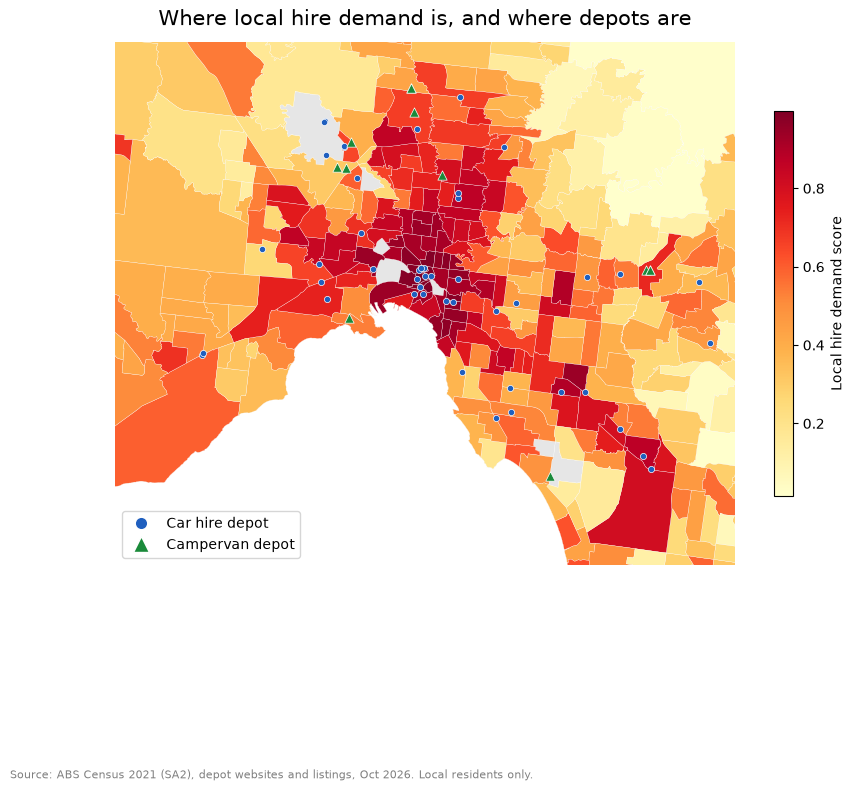

In [17]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(10, 10))

# Background: removed areas in grey, then suburbs shaded by demand
g34.to_crs("EPSG:7855").plot(ax=ax, color="#e6e6e6", edgecolor="white", linewidth=0.2)
df.to_crs("EPSG:7855").plot(
    column="demand_score", cmap="YlOrRd", ax=ax, edgecolor="white", linewidth=0.2,
    legend=True, legend_kwds={"label": "Local hire demand score", "shrink": 0.5},
)

# Depots: blue dots = car, green triangles = campervan
dep = depots_gdf.to_crs("EPSG:7855")
dep[dep["type"] == "car"].plot(ax=ax, color="#1f5fbf", markersize=20, edgecolor="white", linewidth=0.5)
dep[dep["type"] == "campervan"].plot(ax=ax, color="#1a8a3a", marker="^", markersize=45, edgecolor="white", linewidth=0.5)

# Zoom to the metro core, centred on the CBD
cbd = gpd.GeoSeries(gpd.points_from_xy([144.963], [-37.814]), crs="EPSG:4326").to_crs("EPSG:7855").iloc[0]
ax.set_xlim(cbd.x - 32000, cbd.x + 32000)
ax.set_ylim(cbd.y - 30000, cbd.y + 24000)
ax.set_axis_off()

# Legend for pins
ax.legend(handles=[
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#1f5fbf", markersize=9, label="Car hire depot"),
    Line2D([0], [0], marker="^", color="w", markerfacecolor="#1a8a3a", markersize=11, label="Campervan depot"),
], loc="lower left", frameon=True)

ax.set_title("Where local hire demand is, and where depots are", fontsize=15, pad=12)
fig.text(0.02, 0.02, "Source: ABS Census 2021 (SA2), depot websites and listings, Oct 2026. Local residents only.",
         fontsize=8, color="grey")

plt.savefig("outputs/demand_map.png", dpi=300, bbox_inches="tight")
plt.show()

In [18]:
# Friendly region names instead of SA4 codes
regions = {"206": "Inner city", "207": "Inner east", "208": "Inner south", "209": "North east",
           "210": "North west", "211": "Outer east", "212": "South east", "213": "West",
           "214": "Mornington Peninsula"}
df["region"] = df["sa4"].map(regions)

table = (df.sort_values("demand_score", ascending=False)
           .assign(Rank=lambda d: range(1, len(d) + 1))
           [["Rank", "SA2_NAME_2021", "region", "households", "pct_no_car", "pct_renting",
             "pct_25_34", "demand_score", "km_to_car", "nearest_car", "km_to_campervan"]]
           .rename(columns={
               "SA2_NAME_2021": "Suburb (SA2)", "region": "Region", "households": "Households",
               "pct_no_car": "% no car", "pct_renting": "% renting", "pct_25_34": "% aged 25-34",
               "demand_score": "Demand score", "km_to_car": "Km to car depot",
               "nearest_car": "Nearest car depot", "km_to_campervan": "Km to campervan depot"}))

table = table.round({"% no car": 1, "% renting": 1, "% aged 25-34": 1, "Demand score": 2,
                     "Km to car depot": 1, "Km to campervan depot": 1})

# 1. Top 15 overall (slide)
top15 = table.head(15)

# 2. Top 10 outside the inner city (slide)
outer10 = table[table["Region"] != "Inner city"].head(10)

# 3. All high-demand suburbs (top 20%, appendix)
high_demand = table[table["Demand score"] >= df["demand_score"].quantile(0.8).round(2)]

top15.to_csv("outputs/top15_suburbs.csv", index=False)
outer10.to_csv("outputs/top10_outside_inner_city.csv", index=False)
high_demand.to_csv("outputs/high_demand_suburbs_all.csv", index=False)

print(f"Saved. High-demand list has {len(high_demand)} suburbs.")
top15

Saved. High-demand list has 75 suburbs.


,Rank,Suburb (SA2),Region,Households,% no car,% renting,% aged 25-34,Demand score,Km to car depot,Nearest car depot,Km to campervan depot
26,1,Melbourne CBD - West,Inner city,7864,68.8,77.3,45.8,1.00,0.4,Budget Melbourne Downtown,8.6
25,2,Melbourne CBD - North,Inner city,8584,77.6,78.3,39.9,1.00,0.1,Europcar Melbourne City,9.2
30,3,Southbank - East,Inner city,8417,42.2,69.3,43.6,0.99,0.8,Europcar Southbank,8.7
24,4,Melbourne CBD - East,Inner city,4610,66.3,70.2,35.9,0.99,0.3,East Coast Melbourne City Collins St,9.6
16,5,Carlton,Inner city,6951,49.1,73.4,33.6,0.99,1.0,Europcar Melbourne City,8.8
17,6,Docklands,Inner city,7449,40.9,67.6,39.0,0.99,0.9,Budget Southern Cross,7.3
31,7,West Melbourne - Residential,Inner city,3488,36.2,65.6,39.9,0.98,0.6,East Coast Melbourne City A'Beckett St,8.4
43,8,South Yarra - North,Inner city,6092,31.6,66.8,40.1,0.98,0.5,Budget South Yarra,11.0
29,9,Southbank (West) - South Wharf,Inner city,3268,36.3,63.0,36.7,0.98,0.2,Europcar Southbank,8.0
47,10,Collingwood,Inner city,4418,28.8,65.2,36.5,0.97,2.2,East Coast Melbourne City Collins St,8.8
